# Sentiment Analysis using RNN 

### Importing Packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

from tensorflow.keras.layers import LSTM, Embedding, Dense
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

In [2]:
from google_play_scraper import Sort, reviews_all, app

## Scrapping Data from Google Calculator

In [3]:
in_review = reviews_all(
    'com.google.android.calculator',
    sleep_milliseconds=0,
    lang='en',
    country='in',
    sort=Sort.NEWEST,
    count=50
)

In [4]:
in_review

[{'reviewId': '0b5cfbdf-6cfb-4682-bbbc-1f1543d0458e',
  'userName': 'A Google user',
  'userImage': 'https://play-lh.googleusercontent.com/EGemoI2NTXmTsBVtJqk8jxF9rh8ApRWfsIMQSt2uE4OcpQqbFu7f7NbTK05lx80nuSijCz7sc3a277R67g',
  'content': 'AKAZAF',
  'score': 5,
  'thumbsUpCount': 0,
  'reviewCreatedVersion': None,
  'at': datetime.datetime(2026, 10, 25, 22, 7, 40),
  'replyContent': None,
  'repliedAt': None,
  'appVersion': None},
 {'reviewId': '7c50f998-c0d2-4758-9b40-e5ce36cd2cf4',
  'userName': 'A Google user',
  'userImage': 'https://play-lh.googleusercontent.com/EGemoI2NTXmTsBVtJqk8jxF9rh8ApRWfsIMQSt2uE4OcpQqbFu7f7NbTK05lx80nuSijCz7sc3a277R67g',
  'content': "the calculator is showing the sums as fractions not as decimals with a decimal point. I thought it was something that I did but I haven't done anything there's nothing that I can change that would make it stop showing fractions especially when I'm adding money and doing a checkbook I don't understand why it does that is there

### Putting the Data in a DataFrame

In [5]:
df = pd.DataFrame(in_review)
data = df.copy()
data.to_csv("reviews.csv")
df.head()

,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion
0,0b5cfbdf-6cfb-4682-bbbc-1f1543d0458e,A Google user,https://play-lh.googleusercontent.com/EGemoI2N...,AKAZAF,5,0,None,2026-10-25 22:07:40,None,None,None
1,7c50f998-c0d2-4758-9b40-e5ce36cd2cf4,A Google user,https://play-lh.googleusercontent.com/EGemoI2N...,the calculator is showing the sums as fraction...,5,0,9.0 (827797324),2026-10-25 19:22:26,None,None,9.0 (827797324)
2,693193ab-c0b9-4581-8859-91a56149a5bb,A Google user,https://play-lh.googleusercontent.com/EGemoI2N...,cant take shortcut,1,0,9.3 (967717812),2026-10-25 18:40:57,None,None,9.3 (967717812)
3,a79ea5b9-ad42-4193-8306-db52a8059abe,A Google user,https://play-lh.googleusercontent.com/EGemoI2N...,to improve with add feature with converter mm ...,3,0,9.3 (967717812),2026-10-25 18:37:00,None,None,9.3 (967717812)
4,7d2ffe0f-0284-418b-a280-de82ad294b11,A Google user,https://play-lh.googleusercontent.com/EGemoI2N...,It's a normal non bug calculator.,5,0,9.3 (967717812),2026-10-25 16:05:13,None,None,9.3 (967717812)


# Converting Score into Sentiment

In [7]:
reviews = pd.DataFrame()
reviews["review"] = df["content"]
reviews["sentiment"] = np.where(df["score"]>2.5,1,0)

In [8]:
reviews.head()

,review,sentiment
0,AKAZAF,1
1,the calculator is showing the sums as fraction...,1
2,cant take shortcut,0
3,to improve with add feature with converter mm ...,1
4,It's a normal non bug calculator.,1


# Spltting the Dataset

In [9]:
x = reviews['review']
y = reviews['sentiment']

In [16]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42
)

# Converting Reviews into Embeddings

In [17]:
tkn = Tokenizer(num_words=5000)
tkn.fit_on_texts(reviews["review"])

In [18]:
x_train = pad_sequences(tkn.texts_to_sequences(x_train), maxlen=250, padding="post")
x_test = pad_sequences(tkn.texts_to_sequences(x_test), maxlen=250, padding="post")

In [21]:
x_train[0]

array([  44,  345,   45,    2,    1,  425,   62,    4,   34,   18,   60,
          4,  506,    2,   15,    1,    9,   11, 1214,    6, 1072,    1,
       1488,   66, 3302,    4, 1011,  696,   26,    6,  367,    1,  247,
         62,    6,  831,    1,  555,   22,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,   

# Creaing a RNN Model

In [22]:
model = Sequential()

In [28]:
model.add(Embedding(input_dim=5000, output_dim=128, input_length=250))
model.add(LSTM(512, dropout=0.2, recurrent_dropout=0.2))
# model.add(LSTM(256))
model.add(Dense(1, activation="sigmoid"))

C:\Users\balaj\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [29]:
model.compile(optimizer='adamw', loss='binary_crossentropy', metrics=['accuracy'])

In [30]:
history = model.fit(x_train, y_train, epochs=5, batch_size=512, validation_split=0.3)

Epoch 1/5


C:\Users\balaj\AppData\Roaming\Python\Python311\site-packages\keras\src\optimizers\base_optimizer.py:862: UserWarning: Gradients do not exist for variables ['sequential/embedding/embeddings', 'sequential/lstm/lstm_cell/kernel', 'sequential/lstm/lstm_cell/recurrent_kernel', 'sequential/lstm/lstm_cell/bias', 'sequential/dense/kernel', 'sequential/dense/bias'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(


69/69 ━━━━━━━━━━━━━━━━━━━━ 131s 2s/step - accuracy: 0.7255 - loss: 0.5961 - val_accuracy: 0.7289 - val_loss: 0.5845
Epoch 2/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 122s 2s/step - accuracy: 0.7278 - loss: 0.5861 - val_accuracy: 0.7289 - val_loss: 0.5845
Epoch 3/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 145s 2s/step - accuracy: 0.7278 - loss: 0.5857 - val_accuracy: 0.7289 - val_loss: 0.5844
Epoch 4/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 133s 2s/step - accuracy: 0.7278 - loss: 0.5860 - val_accuracy: 0.7289 - val_loss: 0.5846
Epoch 5/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 0.7278 - loss: 0.5858 - val_accuracy: 0.7289 - val_loss: 0.5845


# Evaluating Accuracy

In [32]:
model.evaluate(x_test, y_test)

391/391 ━━━━━━━━━━━━━━━━━━━━ 48s 122ms/step - accuracy: 0.7308 - loss: 0.5827


[0.5827469229698181, 0.7307507395744324]

# Plotting Accuracy

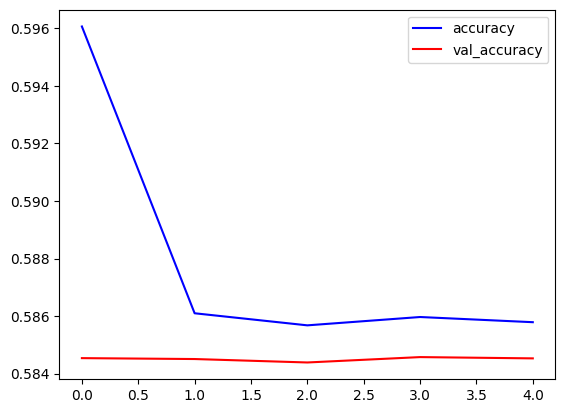

In [31]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], color='blue', label='accuracy')
plt.plot(history.history["val_loss"], color='red', label='val_accuracy')
plt.legend()
plt.show()